# Sift — a classical spam classifier, end to end

**TF-IDF + message statistics → linear model → precision-weighted decision threshold**

This notebook is the documented core of the Sift project. It explains and
reproduces the model that the Django API serves: no deep learning, no GPU, no
hidden preprocessing. Every design decision — de-duplication, feature views,
model comparison, threshold tuning, and the final evaluation — is shown below.

### Contents

1. [The dataset](#1-the-dataset)
2. [Cleaning and leak-free splitting](#2-cleaning-and-leak-free-splitting)
3. [Feature engineering](#3-feature-engineering)
4. [Candidate models](#4-candidate-models)
5. [Choosing a decision threshold](#5-choosing-a-decision-threshold)
6. [Final test evaluation](#6-final-test-evaluation)
7. [Explainability](#7-explainability)
8. [The production artifact](#8-the-production-artifact)
9. [Limitations and next steps](#9-limitations-and-next-steps)

> **Runtime note.** A full training run takes roughly 10–15 minutes and fits a
> 230k-feature matrix. To keep this notebook quick, the walkthrough below uses a
> stratified **14,000-message sample** (`DEMO_ROWS`). Set `DEMO_ROWS = None` to
> use all ~76k clean messages and reproduce the production numbers from
> scratch. The last section loads the real artifact and its `metrics.json`, so
> the headline figures are always the production ones.

In [1]:
import gc
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

# Find the repository root no matter which directory Jupyter was launched from.
ROOT = Path.cwd()
while not (ROOT / "ml").is_dir() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from ml.data import load_dataset, split_dataset
from ml.evaluate import (
    binary_metrics,
    choose_threshold,
    predict_scores,
    top_feature_rows,
    top_features,
)
from ml.features import TextStats, build_feature_union
from ml.predict import load_metrics, load_model, predict_many, predict_text

DATA_PATH = ROOT / "combined_data.csv"
ARTIFACT_DIR = ROOT / "ml" / "artifacts"
DEMO_ROWS = 14_000          # set to None for a full training run
RANDOM_STATE = 7

# The project palette keeps charts consistent with the web UI.
SPAM = "#C96F4F"
HAM = "#6B7F5B"
INK = "#2E3A2F"
SAND = "#D9C9B2"
CREAM = "#F8F6EE"
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.edgecolor": SAND,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlesize": 12,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": INK,
        "ytick.color": INK,
        "text.color": INK,
        "font.family": "DejaVu Sans",
        "figure.dpi": 120,
        "figure.figsize": (9, 4),
    }
)

print("Repository:", ROOT)
print("Dataset exists:", DATA_PATH.exists())

Repository: D:\Code-Base\Git-Clones\Spam-classifire
Dataset exists: True


## 1. The dataset

`combined_data.csv` contains **83,448 labelled messages** with two columns:

| column | meaning |
| --- | --- |
| `text` | the raw message / email body |
| `label` | `1` = spam, `0` = ham |

The convention in this project is fixed: **1 means spam**. The API exposes the
readable strings `"spam"` and `"ham"`; the numeric form is only used for the
model. The corpus is fairly balanced, which makes accuracy a less misleading
metric than it would be on a 1:100 inbox, but precision still matters more than
recall for a spam filter: wrongly deleting a real invoice is expensive.

In [2]:
raw = pd.read_csv(DATA_PATH, usecols=["label", "text"])
raw["text"] = raw["text"].astype(str)

print(f"Rows: {len(raw):,}")
print(f"Nulls: {raw.isna().sum().to_dict()}")
print("Label counts:", raw["label"].value_counts().to_dict())
print("Exact duplicate texts:", int(raw["text"].duplicated().sum()))
display(raw.head(3))

lengths = raw["text"].str.len()
print(
    "Characters — mean: {:.0f} | median: {:.0f} | p95: {:.0f} | max: {:,}".format(
        lengths.mean(), lengths.median(), lengths.quantile(0.95), lengths.max()
    )
)

Rows: 83,448
Nulls: {'label': 0, 'text': 0}
Label counts: {1: 43910, 0: 39538}
Exact duplicate texts: 2


,label,text
0,1,ounce feather bowl hummingbird opec moment ala...
1,1,wulvob get your medircations online qnb ikud v...
2,0,computer connection from cnn com wednesday es...


Characters — mean: 1663 | median: 879 | p95: 4899 | max: 598,705


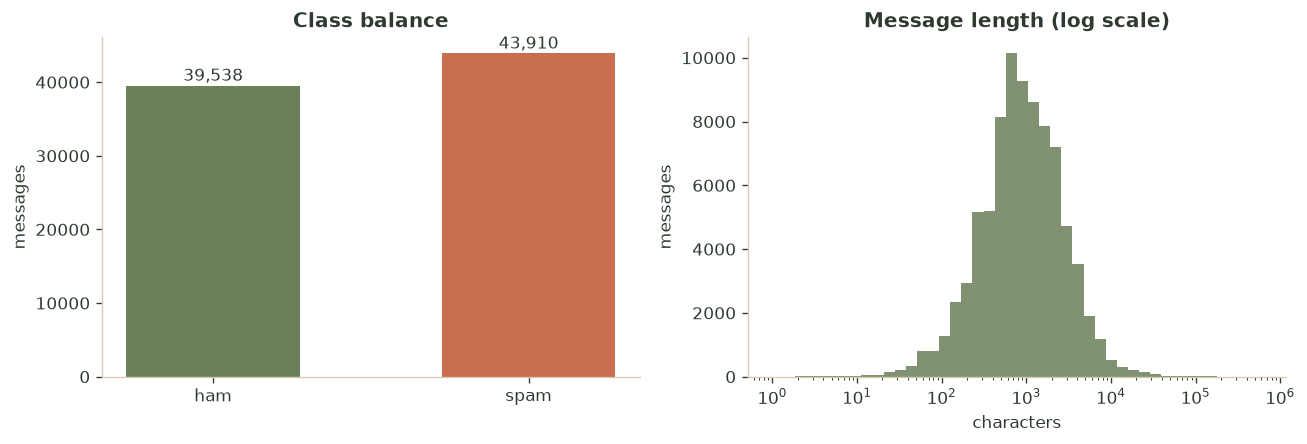

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

counts = raw["label"].map({0: "ham", 1: "spam"}).value_counts().reindex(["ham", "spam"])
axes[0].bar(counts.index, counts.values, color=[HAM, SPAM], width=0.55)
axes[0].set_title("Class balance")
axes[0].set_ylabel("messages")
for index, value in enumerate(counts.values):
    axes[0].text(index, value + counts.max() * 0.015, f"{value:,}", ha="center", fontsize=10)

# Long email threads hide the useful signal in a heavy tail, so use log-spaced bins.
bins = np.logspace(0, np.log10(lengths.clip(lower=1).max()), 45)
axes[1].hist(lengths.clip(lower=1), bins=bins, color=HAM, alpha=0.85)
axes[1].set_xscale("log")
axes[1].set_title("Message length (log scale)")
axes[1].set_xlabel("characters")
axes[1].set_ylabel("messages")
plt.tight_layout()
plt.show()

del raw, lengths
_ = gc.collect()

### Cleaning decisions

Spam corpora are full of duplicates: the same campaign lands in thousands of
inboxes, and public datasets merge scraped copies. If a near-identical message
appears in both training and test data, the test score is inflated.

`ml.data.load_dataset` therefore:

- normalises newlines, strips null bytes, and truncates each message to 20,000
  characters (the longest emails are ~600k characters and add no vocabulary);
- removes **exact duplicates** after case/punctuation normalisation;
- removes **near duplicates** using a 64-bit SimHash over word 3-shingles with
  LSH banding (Hamming distance ≤ 3);
- keeps the first occurrence, which is deterministic for a fixed row order.

This is deliberately stricter than "drop `.duplicated()`", which found only 2
exact copies in the raw file. Normalisation and SimHash find thousands more.

In [4]:
started = time.perf_counter()
dataset = load_dataset(
    DATA_PATH,
    sample=DEMO_ROWS,
    drop_near_duplicates=True,
    random_state=RANDOM_STATE,
)
print(f"Load + clean: {time.perf_counter() - started:.1f}s")

stats = dataset.stats
display(
    pd.DataFrame(
        {
            "value": [
                stats["rows_loaded"],
                stats["rows_clean"],
                stats["exact_duplicates_removed"],
                stats["near_duplicates_removed"],
                stats["label_counts"]["ham"],
                stats["label_counts"]["spam"],
                stats["text_length"]["median"],
                stats["text_length"]["max"],
            ]
        },
        index=[
            "rows loaded",
            "clean rows used (sample)",
            "exact duplicates removed",
            "near duplicates removed",
            "ham",
            "spam",
            "median characters",
            "max characters",
        ],
    )
)

display(dataset.X.head(2).to_frame("text"))

Loaded 83,448 rows -> 14,000 clean rows (697 exact and 6,591 near duplicates removed)
Labels: ham=6,799 spam=7,201
Load + clean: 47.9s


,value
rows loaded,83448
clean rows used (sample),14000
exact duplicates removed,697
near duplicates removed,6591
ham,6799
spam,7201
median characters,820
max characters,20000


,text
0,hey ! just checking out the new machine . i se...
1,dear users i have a very simple question i hav...


## 2. Cleaning and leak-free splitting

The split is stratified **80/10/10** (train / validation / test) and happens
before any vectorizer is fitted. That ordering is essential:

- the vectorizers learn vocabulary and IDF weights only from the training fold;
- the validation fold selects the model family, regularisation, and threshold;
- the test fold is touched once, at the very end.

Fitting a `TfidfVectorizer` on the whole dataset first would leak test-set
vocabulary and document frequencies into training, producing an optimistic
score. The pipeline below avoids that by fitting the feature union on `X_train`
only.

In [5]:
split = split_dataset(dataset, random_state=RANDOM_STATE)
print(split.summary())

def preview(text: str, limit: int = 420) -> str:
    # The merged corpus contains old control characters; keep notebook output clean.
    text = "".join(ch if ch.isprintable() or ch in "\n\t" else " " for ch in text)
    return text[:limit] + ("…" if len(text) > limit else "")


for name, part in [("SPAM", 1), ("HAM", 0)]:
    examples = split.X_train[split.y_train == part].head(1).tolist()
    print(f"\n{name} example:\n{preview(examples[0])}")

{'train': 11200, 'validation': 1400, 'test': 1400}

SPAM example:
good day visit our new online pharmacy store and save upto escapenumber todays special offers viagra for as low as escapenumber escapenumber per dose cialis super viagra for as low as escapenumber escapenumber per dose levitra for as low as escapenumber escapenumber per dose and much much more surprises for you today it ll take escapenumber minutes to be ready for action most needed medications are available viagra c…

HAM example:
sorry i responded a bit too hastily last night without testing the two functions properly brian's is shorter but i think the one in my post is a bit more robust indeed 'fescapenumber' only works if at least one of the arguments is named otherwise 'nm' is null and 'nchar nm i ' fails 'fescapenumber' seems to have all combinations covered thanks again fescapenumber function m as list match call expand dots true escapen…


## 3. Feature engineering

The model sees three complementary views of each message:

| view | configuration | why |
| --- | --- | --- |
| **Word TF-IDF** | 1–2 grams, 150k features, `min_df=2`, sublinear TF | phrases such as “click here”, “act now”, “unclaimed prize” |
| **Character TF-IDF** | `char_wb` 3–5 grams, 80k features, first 4,000 characters | obfuscation (“fr33 m0ney”, “V1AGRA”), morphology, punctuation tricks |
| **Text statistics** | 23 dense features, `MaxAbsScaler` | link/email/HTML counts, shouting, digits, punctuation abuse, urgency/money/marketing keyword families |

The views are concatenated by a scikit-learn `FeatureUnion` with weights
`1.0 / 0.65 / 0.35`, so character n-grams and hand-built statistics support the
word view without drowning it.

For a term $t$ in document $d$, sublinear TF-IDF is

$$
\mathrm{tf}(t,d) = 1 + \log c(t,d), \qquad
\mathrm{idf}(t) = \log\frac{1 + N}{1 + \mathrm{df}(t)} + 1,
\qquad
w(t,d) = \mathrm{tf}(t,d)\cdot\mathrm{idf}(t).
$$

The classifier is a linear model, so the score for a message is a weighted sum
of its features plus an intercept. That linearity is what makes the
explanations in section 7 possible.

In [6]:
union = build_feature_union()
X_train = union.fit_transform(split.X_train, split.y_train)
X_val = union.transform(split.X_val)
X_test = union.transform(split.X_test)

print(f"Train matrix: {X_train.shape[0]:,} rows × {X_train.shape[1]:,} features")
print(f"Non-zero values: {X_train.nnz / 1e6:.1f}M ({X_train.nnz / X_train.shape[0]:.0f} per message)")
print(f"Average density: {X_train.nnz / (X_train.shape[0] * X_train.shape[1]):.4%}")

widths = {
    "word": len(union.transformer_list[0][1].get_feature_names_out()),
    "char": len(union.transformer_list[1][1].get_feature_names_out()),
    "stats": len(TextStats.FEATURE_NAMES),
}
display(pd.Series(widths, name="features").to_frame())

print("A few word features:", list(union.transformer_list[0][1].get_feature_names_out()[:12]))
print("Text statistics:", ", ".join(TextStats.FEATURE_NAMES))

Train matrix: 11,200 rows × 230,023 features
Non-zero values: 15.5M (1387 per message)
Average density: 0.6032%


,features
word,150000
char,80000
stats,23


A few word features: ['00', '00 00', '00 000', '00 01', '00 02', '00 03', '00 0500', '00 0600', '00 08', '00 10', '00 11', '00 12']
Text statistics: log_chars, log_words, avg_word_len, max_word_len, unique_word_ratio, digit_ratio, uppercase_ratio, punctuation_ratio, non_ascii_ratio, exclamation_per_kchar, question_per_kchar, dollar_per_kchar, percent_per_kchar, url_count, email_address_count, html_tag_count, number_token_ratio, caps_word_ratio, log_lines, repeated_punctuation, urgency_hits, money_hits, marketing_hits


### A quick look at vocabulary

The plot below is **not** the model; it is an exploratory log-odds comparison of
word and bigram frequencies between spam and ham in the training split. It makes
the corpus's signal visible before the model combines 230k features. A small
additive smoothing (+1) prevents rare terms from dominating.

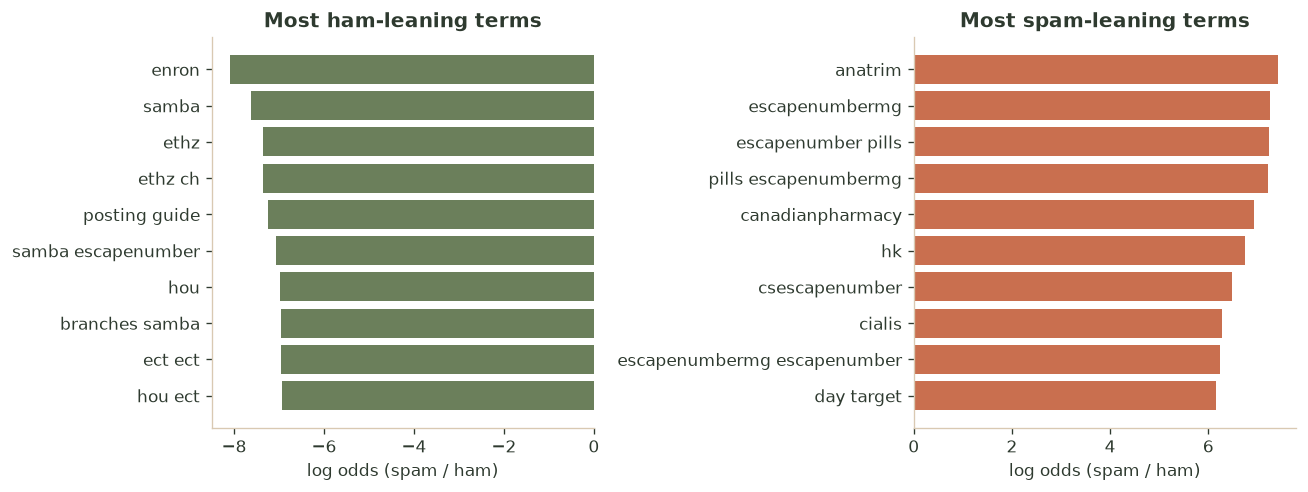

In [7]:
counter = CountVectorizer(
    ngram_range=(1, 2),
    min_df=5,
    max_features=40_000,
    stop_words="english",
)
counts = counter.fit_transform(split.X_train)
names = counter.get_feature_names_out()
y_train_array = split.y_train.to_numpy()

spam_counts = np.asarray(counts[y_train_array == 1].sum(axis=0)).ravel()
ham_counts = np.asarray(counts[y_train_array == 0].sum(axis=0)).ravel()
spam_rate = (spam_counts + 1) / (spam_counts.sum() + len(names))
ham_rate = (ham_counts + 1) / (ham_counts.sum() + len(names))
log_odds = np.log(spam_rate) - np.log(ham_rate)

spam_top = np.argsort(log_odds)[-10:][::-1]
ham_top = np.argsort(log_odds)[:10]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].barh([names[i] for i in ham_top][::-1], log_odds[ham_top][::-1], color=HAM)
axes[0].set_title("Most ham-leaning terms")
axes[0].set_xlabel("log odds (spam / ham)")

axes[1].barh([names[i] for i in spam_top][::-1], log_odds[spam_top][::-1], color=SPAM)
axes[1].set_title("Most spam-leaning terms")
axes[1].set_xlabel("log odds (spam / ham)")
plt.tight_layout()
plt.show()

## 4. Candidate models

Three classical families are compared on the validation split:

1. **Logistic regression** (`liblinear`, L2, `C=2`) — strong sparse-text baseline,
   native probabilities, coefficients for explanations.
2. **Calibrated Linear SVC** (`C=0.5`, sigmoid calibration, 3 folds) — often a
   little sharper at the decision boundary; calibration turns margins into
   usable probabilities.
3. **Complement Naive Bayes** (`alpha=0.3`) — extremely fast, designed for
   imbalanced text; a useful sanity check, rarely the winner on rich features.

Selection uses **average precision (PR-AUC)** rather than accuracy. Accuracy
moves very little near the top of the curve, while PR-AUC reflects how well the
model ranks spam above ham across all thresholds — important because the
decision threshold is tuned separately afterwards.

> This demo fits the classifiers on the already-transformed training matrix. In
> a production retrain, `ml.train` refits the vectorizers on train + validation
> after choosing the family, so the final artifact benefits from 10% more text.

In [8]:
candidates = {
    "Logistic regression (C=2)": LogisticRegression(
        C=2.0, solver="liblinear", max_iter=2000, random_state=RANDOM_STATE
    ),
    "Calibrated Linear SVC (C=0.5)": CalibratedClassifierCV(
        estimator=LinearSVC(C=0.5, dual="auto", random_state=RANDOM_STATE),
        method="sigmoid",
        cv=3,
    ),
    "Complement NB (alpha=0.3)": ComplementNB(alpha=0.3),
}

rows = []
fitted = {}
val_scores = {}
thresholds = {}

for name, estimator in candidates.items():
    started = time.perf_counter()
    estimator.fit(X_train, split.y_train)
    fit_seconds = time.perf_counter() - started

    scores = predict_scores(estimator, X_val)
    threshold = choose_threshold(split.y_val, scores, beta=0.5)
    metrics = binary_metrics(split.y_val, scores, threshold)

    fitted[name] = estimator
    val_scores[name] = scores
    thresholds[name] = threshold
    rows.append(
        {
            "model": name,
            "threshold": threshold,
            "precision": metrics["precision"],
            "recall": metrics["recall"],
            "f1": metrics["f1"],
            "f0_5": metrics["f0_5"],
            "pr_auc": metrics["average_precision"],
            "roc_auc": metrics["roc_auc"],
            "fit_s": round(fit_seconds, 2),
        }
    )

comparison = pd.DataFrame(rows).sort_values("pr_auc", ascending=False).reset_index(drop=True)
best_name = comparison.loc[0, "model"]
best_clf = fitted[best_name]
best_threshold = thresholds[best_name]
best_val_scores = val_scores[best_name]

display(comparison.round(4))
print(f"Selected on PR-AUC: {best_name} at threshold {best_threshold:.3f}")

,model,threshold,precision,recall,f1,f0_5,pr_auc,roc_auc,fit_s
0,Calibrated Linear SVC (C=0.5),0.6956,0.9874,0.9806,0.9840,0.9860,0.9984,0.9984,3.39
1,Logistic regression (C=2),0.6484,0.9860,0.9792,0.9826,0.9846,0.9981,0.9981,3.41
2,Complement NB (alpha=0.3),0.6763,0.9858,0.9611,0.9733,0.9807,0.9974,0.9974,0.06


Selected on PR-AUC: Calibrated Linear SVC (C=0.5) at threshold 0.696


## 5. Choosing a decision threshold

A classifier outputs a score; a **threshold** turns it into a decision. The
default 0.5 is rarely the right cut-off for spam. Because a false positive
(real mail marked spam) is more damaging than a false negative (junk delivered),
the project maximises **F$_{0.5}$**:

$$
F_\beta = (1+\beta^2)\frac{\mathrm{precision}\cdot\mathrm{recall}}{\beta^2\cdot\mathrm{precision}+\mathrm{recall}},
\qquad \beta = 0.5.
$$

With $\beta<1$, precision is weighted more heavily than recall. The threshold is
chosen on the **validation** split and then frozen for the test split. The scan
is over observed score quantiles, not an arbitrary 0.01 grid, so it adapts to
the calibrated probability distribution.

The vertical line marks the chosen cut-off. Notice the trade-off: lowering it
catches more spam but also flags more real mail.

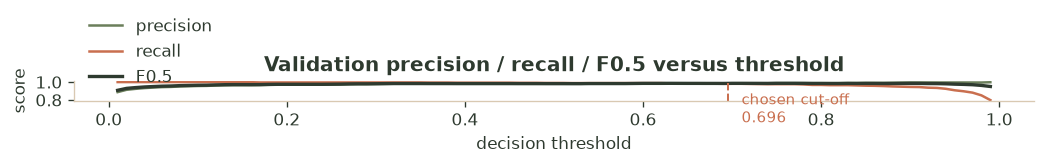

In [9]:
from sklearn.metrics import fbeta_score, precision_score, recall_score

grid = np.linspace(0.01, 0.99, 99)
curve = []
for threshold in grid:
    decisions = (best_val_scores >= threshold).astype(int)
    curve.append(
        (
            threshold,
            precision_score(split.y_val, decisions, zero_division=0),
            recall_score(split.y_val, decisions, zero_division=0),
            fbeta_score(split.y_val, decisions, beta=0.5, zero_division=0),
        )
    )
curve = pd.DataFrame(curve, columns=["threshold", "precision", "recall", "f0_5"])

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(curve["threshold"], curve["precision"], color=HAM, label="precision")
ax.plot(curve["threshold"], curve["recall"], color=SPAM, label="recall")
ax.plot(curve["threshold"], curve["f0_5"], color=INK, linewidth=2, label="F0.5")
ax.axvline(best_threshold, color=SPAM, linestyle="--", linewidth=1.2)
ax.text(best_threshold + 0.015, 0.55, f"chosen cut-off\n{best_threshold:.3f}", fontsize=9, color=SPAM)
ax.set_xlabel("decision threshold")
ax.set_ylabel("score")
ax.set_title("Validation precision / recall / F0.5 versus threshold")
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

## 6. Final test evaluation

The chosen model and threshold are now applied **once** to the held-out test
split. The confusion matrix is the clearest summary: false positives are real
messages incorrectly blocked, false negatives are spam that reached the inbox.
Precision, recall, F1, F0.5, PR-AUC, ROC-AUC, and the Brier score are reported
together because no single number tells the whole story.

The demo sample is smaller than the production run, so these figures will be a
little noisier than the artifact's ~99% test scores.

,test score
threshold,0.6956
accuracy,0.9779
precision,0.9900
recall,0.9667
f1,0.9782
f0_5,0.9853
pr_auc,0.9989
roc_auc,0.9989
brier,0.0133


,tn,fp,fn,tp
0,673,7,24,696


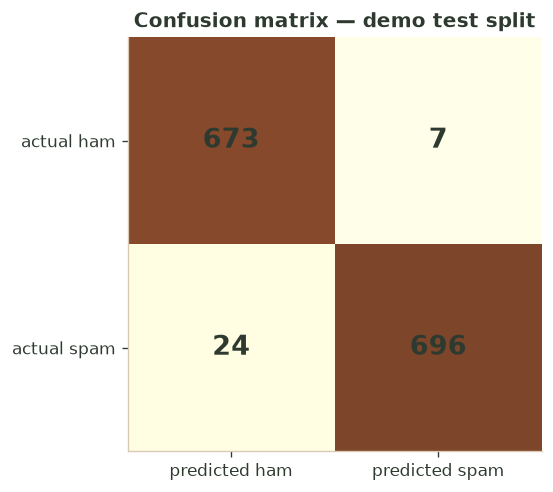

In [10]:
# A pre-fitted Pipeline wrapper reuses the union/classifier and enables the
# explanation helpers, which expect pipeline.named_steps["features"].
demo_pipeline = Pipeline([("features", union), ("clf", best_clf)])
demo_pipeline.threshold_ = best_threshold
demo_pipeline.version_ = "notebook-demo"

test_scores = predict_scores(best_clf, X_test)
test_metrics = binary_metrics(split.y_test, test_scores, best_threshold)

summary = pd.Series(
    {
        "threshold": test_metrics["threshold"],
        "accuracy": test_metrics["accuracy"],
        "precision": test_metrics["precision"],
        "recall": test_metrics["recall"],
        "f1": test_metrics["f1"],
        "f0_5": test_metrics["f0_5"],
        "pr_auc": test_metrics["average_precision"],
        "roc_auc": test_metrics["roc_auc"],
        "brier": test_metrics["brier"],
    }
)
display(summary.round(4).to_frame("test score"))
display(pd.DataFrame([test_metrics["confusion_matrix"]]))

cm = np.array(
    [
        [test_metrics["confusion_matrix"]["tn"], test_metrics["confusion_matrix"]["fp"]],
        [test_metrics["confusion_matrix"]["fn"], test_metrics["confusion_matrix"]["tp"]],
    ]
)

fig, ax = plt.subplots(figsize=(5.4, 4.2))
ax.imshow(cm, cmap="YlOrBr", alpha=0.85)
ax.set_xticks([0, 1], labels=["predicted ham", "predicted spam"])
ax.set_yticks([0, 1], labels=["actual ham", "actual spam"])
for row in range(2):
    for col in range(2):
        ax.text(
            col,
            row,
            f"{cm[row, col]:,}",
            ha="center",
            va="center",
            fontsize=16,
            fontweight="bold",
            color=INK,
        )
ax.set_title("Confusion matrix — demo test split")
plt.tight_layout()
plt.show()

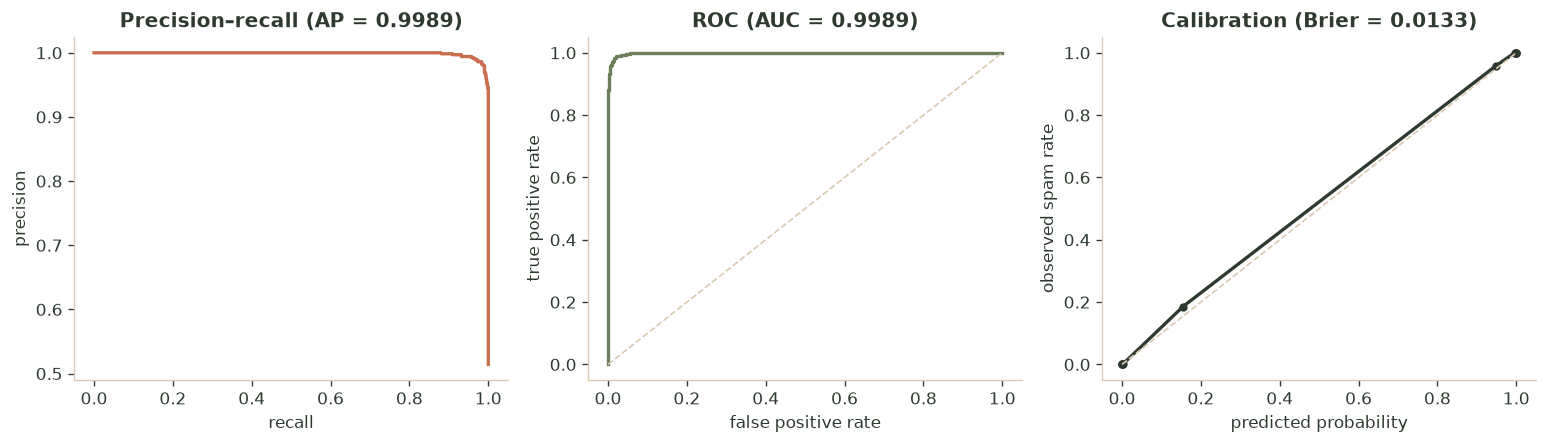

In [11]:
precision_curve, recall_curve, _ = precision_recall_curve(split.y_test, test_scores)
fpr, tpr, _ = roc_curve(split.y_test, test_scores)
prob_true, prob_pred = calibration_curve(split.y_test, test_scores, n_bins=10, strategy="quantile")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

axes[0].plot(recall_curve, precision_curve, color=SPAM, linewidth=2)
axes[0].set_xlabel("recall")
axes[0].set_ylabel("precision")
axes[0].set_title(f"Precision–recall (AP = {test_metrics['average_precision']:.4f})")

axes[1].plot(fpr, tpr, color=HAM, linewidth=2)
axes[1].plot([0, 1], [0, 1], color=SAND, linestyle="--", linewidth=1)
axes[1].set_xlabel("false positive rate")
axes[1].set_ylabel("true positive rate")
axes[1].set_title(f"ROC (AUC = {test_metrics['roc_auc']:.4f})")

axes[2].plot(prob_pred, prob_true, marker="o", color=INK, linewidth=2, markersize=4)
axes[2].plot([0, 1], [0, 1], color=SAND, linestyle="--", linewidth=1)
axes[2].set_xlabel("predicted probability")
axes[2].set_ylabel("observed spam rate")
axes[2].set_title(f"Calibration (Brier = {test_metrics['brier']:.4f})")

plt.tight_layout()
plt.show()

## 7. Explainability

A linear model's decision is a sum of signed feature contributions. For one
message, the contribution of feature $j$ is

$$
c_j = w_j \cdot x_j,
$$

where $x_j$ is the TF-IDF or scaled-statistic value. Positive contributions push
toward spam, negative contributions pull toward ham. The API returns the
largest-magnitude contributions for every single-message prediction, which is
why the UI can show "words that moved the needle" rather than a black-box score.

Global coefficients answer a different question: which features are spammy in
general? They are useful, but can be misleading — a word like `free` may appear
in both classes, and its weight reflects the *residual* association after all
other features are considered.

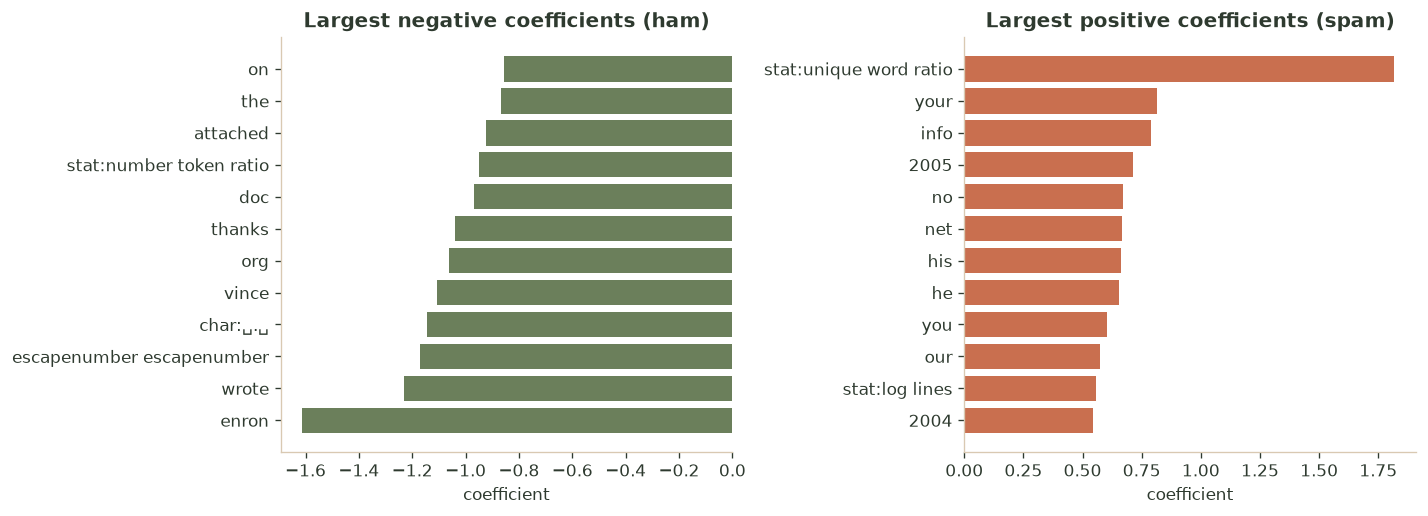

In [12]:
def pretty_feature(name: str) -> str:
    name = str(name)
    if name.startswith("~"):
        return "char:" + name[1:].replace(" ", "␣")
    if name.startswith("stat:"):
        return "stat:" + name[5:].replace("_", " ")
    return name


global_signals = top_features(demo_pipeline, n=12)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, key, color, title in [
    (axes[0], "ham", HAM, "Largest negative coefficients (ham)"),
    (axes[1], "spam", SPAM, "Largest positive coefficients (spam)"),
]:
    rows = global_signals[key]
    labels = [pretty_feature(row["word"]) for row in rows][::-1]
    values = [row["weight"] for row in rows][::-1]
    ax.barh(labels, values, color=color)
    ax.set_title(title)
    ax.set_xlabel("coefficient")
plt.tight_layout()
plt.show()

In [13]:
examples = {
    "Phishing / prize": (
        "Congratulations! You have won a free cash prize. Click here immediately "
        "to claim your money before this offer expires."
    ),
    "Legitimate work mail": (
        "Hi Maya, the design review moved to Thursday at 10:00. Could you send "
        "the updated copy before then? Thanks, Sam"
    ),
    "Promotional newsletter": (
        "This week only: 30% off all courses. Use code LEARN30 at checkout. "
        "Unsubscribe at any time."
    ),
}

for label, text in examples.items():
    result = predict_text(demo_pipeline, text, threshold=best_threshold, top_n=6)
    display(
        Markdown(
            f"**{label}** → `{result['label']}` "
            f"({result['spam_probability']:.1%} spam, cut-off {result['threshold']:.3f})"
        )
    )
    display(pd.DataFrame(result["top_words"]))

**Phishing / prize** → `spam` (100.0% spam, cut-off 0.696)

,word,weight
0,offer,0.0616
1,your,0.0476
2,money,0.0449
3,congratulations,-0.0415
4,claim,0.0337
5,to,-0.0331


**Legitimate work mail** → `ham` (9.9% spam, cut-off 0.696)

,word,weight
0,thanks,-0.1008
1,the,-0.0620
2,thursday,-0.0462
3,could you,-0.0357
4,to,-0.0353
5,review,-0.0316


**Promotional newsletter** → `ham` (6.2% spam, cut-off 0.696)

,word,weight
0,this week,-0.0633
1,code,-0.0618
2,week,-0.0606
3,at,-0.0493
4,only,0.0439
5,use,-0.0398


## 8. The production artifact

The notebook has demonstrated the workflow on a fast sample. The deployed
artifact was trained by the same code on the **full clean corpus**:

```bash
python -m ml.train
```

That command writes `ml/artifacts/spam_pipeline.joblib` and
`ml/artifacts/metrics.json`. The Django backend loads the joblib file once per
worker and serves predictions from it.

The table below reads the real metrics sidecar, so it is not a sample estimate.
The production artifact was fitted on **68,514 messages** (60,901 train +
7,613 validation) and evaluated on **7,613 untouched test messages**.

In [14]:
production_metrics = load_metrics(ARTIFACT_DIR / "metrics.json")
production_test = production_metrics["test"]["at_tuned_threshold"]
production_at_05 = production_metrics["test"]["at_0.5"]

production_table = pd.DataFrame(
    {
        f"cut-off {production_metrics['model']['threshold']:.4f}": [
            production_test["accuracy"],
            production_test["precision"],
            production_test["recall"],
            production_test["f1"],
            production_test["f0_5"],
            production_test["average_precision"],
            production_test["roc_auc"],
            production_test["brier"],
        ],
        "default 0.5000": [
            production_at_05["accuracy"],
            production_at_05["precision"],
            production_at_05["recall"],
            production_at_05["f1"],
            production_at_05["f0_5"],
            production_at_05["average_precision"],
            production_at_05["roc_auc"],
            production_at_05["brier"],
        ],
    },
    index=["accuracy", "precision", "recall", "F1", "F0.5", "PR-AUC", "ROC-AUC", "Brier"],
)
display(production_table.round(4))

display(
    pd.DataFrame(production_metrics["comparison"])[
        ["name", "precision", "recall", "f1", "f0_5", "average_precision", "fit_seconds"]
    ].round(4)
)

print("Confusion matrix:", production_test["confusion_matrix"])
print("Artifact:", production_metrics.get("artifact"))
print("Batch latency:", f"{production_metrics.get('latency_ms_per_email', 0):.2f} ms/email")

,cut-off 0.7104,default 0.5000
accuracy,0.9883,0.9896
precision,0.9951,0.9856
recall,0.9822,0.9944
F1,0.9886,0.9900
F0.5,0.9925,0.9874
PR-AUC,0.9992,0.9992
ROC-AUC,0.9993,0.9993
Brier,0.0089,0.0089


,name,precision,recall,f1,f0_5,average_precision,fit_seconds
0,LogisticRegression,0.9931,0.9837,0.9884,0.9912,0.9986,28.80
1,CalibratedLinearSVC,0.9933,0.9885,0.9909,0.9924,0.9983,10.16
2,ComplementNB,0.9885,0.9603,0.9742,0.9827,0.9958,0.18


Confusion matrix: {'tn': 3666, 'fp': 19, 'fn': 70, 'tp': 3858}
Artifact: {'path': 'spam_pipeline.joblib', 'size_mb': 4.15}
Batch latency: 1.90 ms/email


In [15]:
production_model = load_model()
print("Loaded version:", production_model.version_)
print("Stored threshold:", production_model.threshold_)

for label, text in examples.items():
    result = predict_text(production_model, text, top_n=6)
    display(
        Markdown(
            f"**{label}** → `{result['label']}` at "
            f"**{result['spam_probability']:.2%}** spam probability "
            f"(model {result['model_version']})"
        )
    )

# Warm the caches once, then time vectorised batch inference.
warmup = split.X_test.iloc[:50].tolist()
predict_many(production_model, warmup)
timed_texts = split.X_test.iloc[:200].tolist()
started = time.perf_counter()
predict_many(production_model, timed_texts)
elapsed = time.perf_counter() - started
print(f"\nVectorised inference: {elapsed * 1000 / len(timed_texts):.2f} ms/message over {len(timed_texts)} messages")

Loaded version: 2.0.0
Stored threshold: 0.7104


**Phishing / prize** → `spam` at **99.16%** spam probability (model 2.0.0)

**Legitimate work mail** → `ham` at **14.45%** spam probability (model 2.0.0)

**Promotional newsletter** → `ham` at **28.87%** spam probability (model 2.0.0)


Vectorised inference: 2.67 ms/message over 200 messages


## 9. Limitations and next steps

**Known limitations**

- **Dataset drift.** The corpus is a merged public dataset. Vocabulary,
  campaigns, and writing styles change; a production filter needs monitoring and
  periodic retraining with fresh, labelled mail.
- **Near-duplicate removal is aggressive.** It protects the test score from
  leakage, but it can drop legitimate template messages (newsletters, alerts)
  that appear many times. The production dataset keeps 76,127 of 83,448 rows.
- **Short messages are hard.** A one-line message has little evidence; the model
  can be over-confident. The API reports a probability and threshold rather than
  a bare label for this reason.
- **Adversarial obfuscation.** Character n-grams help with `fr33 m0ney`, but a
  determined attacker can still evade a bag-of-features model.
- **No headers, attachments, or sender reputation.** The model reads the message
  body only. Real mail security combines content with authentication (SPF/DKIM),
  link reputation, and user feedback.
- **Threshold trade-off.** At the chosen cut-off the production system made 19
  false positives and 70 false negatives on 7,613 test messages. That is a
  deliberate precision-first choice, not a claim of perfection.

**Useful next steps**

1. Collect user feedback ("mark as spam" / "not spam") and retrain with it.
2. Add calibrated per-domain thresholds and a review queue for borderline
   scores (for example, 0.45–0.75).
3. Periodically rebuild the artifact in CI and compare metrics before promoting.
4. Add authentication and per-user rate limits before exposing the API publicly.
5. Consider gradient boosting on the same features if accuracy plateaus — still
   classical ML, but much harder to explain per message.

### Reproduce

```bash
# From the repository root, with the virtual environment active
python -m ml.train                 # full training (~10–15 min)
jupyter lab ml/notebooks/spam_classifier.ipynb
```

The notebook is executed top-to-bottom; plots and tables above are stored
outputs. Set `DEMO_ROWS = None` to run the walkthrough on the full corpus.